# 1. 배송 지연 + 쿠폰

| 세부 기능 | 판매자 질문 예시 | 도구 |
| --- | --- | --- |
| 1-1 지연 책임 분해 | "이번 달 지연은 누구 탓이야?" | `delay_breakdown` |
| 1-2 발송 what-if | "이 주문 며칠 뒤에 보내도 돼?" | `shipping_whatif` |
| 1-3 도착일 안내 | "고객이 언제 오냐고 물어" | `delivery_estimate` |
| 1-4 쿠폰 금액 계산 | "4일 늦을 것 같은데 쿠폰 얼마 줘?" | `coupon_advice` |
| 1-5 쿠폰 예산 배분 | "쿠폰 예산 100헤알, 누구한테 줘?" | `coupon_budget` |
| 1-6 약속일 임박 경고 | "곧 늦을 것 같은 주문 있어?" | `promise_alerts` |

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_asof | 데이터: preprocessing


## 1-1. 지연 책임 분해
판매자가 **발송 마감일을 넘겨서** 택배사에 넘긴 지연(내가 고칠 수 있음)과, 마감 안에 넘겼는데도 늦은 **택배 구간** 지연을 나눠요.

In [2]:
r = st.call('delay_breakdown', {'seller_id': DEMO})
show(r)
print('\n💬', f"배송 {r['orders']}건 중 {r['late_orders']}건이 약속보다 늦었어요. 그중 {r['late_due_to_seller_shipping']}건은 발송 마감을 넘긴 주문이고 "
      f"{r['late_in_transit_only']}건은 택배 구간 문제예요. 마감을 넘기면 지연 확률이 {r['late_rate_if_shipped_late']:.0%}, 지키면 {r['late_rate_if_shipped_on_time']:.0%}예요.")

{
 "orders": 187,
 "late_orders": 21,
 "late_rate": 0.1123,
 "late_due_to_seller_shipping": 18,
 "late_in_transit_only": 3,
 "late_rate_if_shipped_late": 0.3,
 "late_rate_if_shipped_on_time": 0.0236
}

💬 배송 187건 중 21건이 약속보다 늦었어요. 그중 18건은 발송 마감을 넘긴 주문이고 3건은 택배 구간 문제예요. 마감을 넘기면 지연 확률이 30%, 지키면 2%예요.


In [3]:
# 기간을 정해서 볼 수도 있어요
show(st.call('delay_breakdown', {'seller_id': DEMO, 'start': '2018-01-01', 'end': '2018-08-31'}))

{
 "orders": 187,
 "late_orders": 21,
 "late_rate": 0.1123,
 "late_due_to_seller_shipping": 18,
 "late_in_transit_only": 3,
 "late_rate_if_shipped_late": 0.3,
 "late_rate_if_shipped_on_time": 0.0236
}


## 1-2. 발송 what-if
"이 주문을 n일 뒤에 택배사에 넘기면 지연 확률은?" 발송 처리 시간을 바꿔 넣고 예측해요. 모델에는 **단조 제약**을 걸어서 늦게 보낼수록 확률이 내려가는 이상한 결과가 안 나와요 (처음 부를 때 몇 초 동안 학습해요).

{
 "order_id": "55edfc7697e8da852cfed4f2c93787b9",
 "customer_state": "SP",
 "dist_km": 37.4328,
 "promised_days": 11.3867,
 "scenarios": [
  {
   "ship_after_days": 0.5,
   "late_probability": 0.0158
  },
  {
   "ship_after_days": 1,
   "late_probability": 0.0164
  },
  {
   "ship_after_days": 2,
   "late_probability": 0.0197
  },
  {
   "ship_after_days": 3,
   "late_probability": 0.0218
  },
  {
   "ship_after_days": 5,
   "late_probability": 0.0364
  },
  {
   "ship_after_days": 7,
   "late_probability": 0.0907
  },
  {
   "ship_after_days": 10,
   "late_probability": 0.3082
  }
 ],
 "model_auc_future_months": 0.785
}


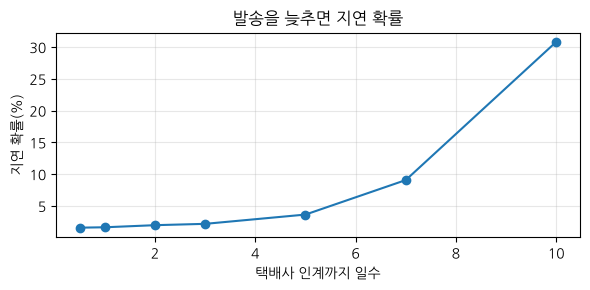

💬 1일 안에 보내면 지연 확률 2%, 7일 뒤면 9%, 10일 뒤면 31%예요. (이 모델은 미래 기간 AUC 0.785)


In [4]:
order = st.valid[st.valid.seller_id == st._sid(DEMO)].sort_values('promised_days').order_id.iloc[0]   # 약속 기간이 짧은 주문
r = st.call('shipping_whatif', {'order_id': order, 'seller_id': DEMO})
show(r)
sc = pd.DataFrame(r['scenarios'])
plt.figure(figsize=(6, 3)); plt.plot(sc.ship_after_days, sc.late_probability * 100, marker='o')
plt.xlabel('택배사 인계까지 일수'); plt.ylabel('지연 확률(%)'); plt.title('발송을 늦추면 지연 확률'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
s1 = sc.set_index('ship_after_days').late_probability
print('💬', f"1일 안에 보내면 지연 확률 {s1.get(1, s1.iloc[0]):.0%}, 7일 뒤면 {s1.get(7):.0%}, 10일 뒤면 {s1.get(10):.0%}예요. (이 모델은 미래 기간 AUC {r['model_auc_future_months']})")

## 1-3. 도착일 안내 (고객 응대용)
구매 시점 정보로 도착일의 **중앙값과 90% 상한**을 예측해요. "보통 며칠, 늦어도 며칠 안"으로 말할 수 있어요.

In [5]:
r = st.call('delivery_estimate', {'order_id': order})
show(r)
print('💬', f"보통 {r['expected_days']:.0f}일 정도 걸려서 {r['expected_date']}쯤 도착하고, 90% 확률로 {r['latest_date_90pct']}까지는 와요. (약속일 {r['promised_date']})")

{
 "order_id": "55edfc7697e8da852cfed4f2c93787b9",
 "purchase_date": "2018-05-13",
 "expected_days": 4.0,
 "within_days_90pct": 8.2,
 "expected_date": "2018-05-17",
 "latest_date_90pct": "2018-05-21",
 "promised_date": "2018-05-25",
 "actual_days": 3.1678
}
💬 보통 4일 정도 걸려서 2018-05-17쯤 도착하고, 90% 확률로 2018-05-21까지는 와요. (약속일 2018-05-25)


## 1-4. 쿠폰 금액 계산
**쿠폰 상한 = 1~2점 리뷰 확률 × 쿠폰이 그걸 막는 비율(가정) × 나쁜 리뷰 하나의 손해**
- 1~2점 확률: 약속 대비 지연 일수별 과거 비율
- 나쁜 리뷰의 손해: 1~2점 리뷰 뒤 4주 판매가 약 6.1% 더 줄었다는 분석 × 상품의 월 판매량 × 가격
- 쿠폰이 막는 비율은 데이터에 없어서 **가정값**(기본 1/3)이에요

In [6]:
rel = st.ps[st.ps.reliable]
popular = rel.iloc[(rel.bad_review_cost - rel.bad_review_cost.median()).abs().argsort().iloc[0]].product_id   # 손해액이 중간쯤인 '보통' 상품
r = st.call('coupon_advice', {'expected_delay_days': 4, 'product_id': popular})
show(r)
print('💬', f"4일 늦으면 1~2점 받을 확률이 {r['low_review_probability']:.0%}예요. 이 상품은 나쁜 리뷰 하나가 한 달에 약 {r['bad_review_cost']:.0f}헤알 손해라서, "
      f"쿠폰은 {r['coupon_cap']:.1f}헤알까지 주는 게 이득이에요. (쿠폰 효과 {r['prevent_share_assumed']:.0%} 가정)")

{
 "expected_delay_days": 4,
 "delay_bin": "4~5일 늦음",
 "low_review_probability": 0.604,
 "bad_review_cost": 14.9725,
 "cost_basis": "상품 자체 값",
 "prevent_share_assumed": 0.3333,
 "coupon_cap": 3.0,
 "order_freight": null,
 "note": "쿠폰이 나쁜 리뷰를 막는 비율은 데이터에 없어서 가정값이에요. prevent_share로 바꿀 수 있어요."
}
💬 4일 늦으면 1~2점 받을 확률이 60%예요. 이 상품은 나쁜 리뷰 하나가 한 달에 약 15헤알 손해라서, 쿠폰은 3.0헤알까지 주는 게 이득이에요. (쿠폰 효과 33% 가정)


In [7]:
# 지연 일수 × 쿠폰 효과 가정별 쿠폰 상한 표
rows = []
for days in [1, 2, 4, 7]:
    for share in [0.2, 1/3, 0.5]:
        r = st.call('coupon_advice', {'expected_delay_days': days, 'product_id': popular, 'prevent_share': share})
        rows.append({'지연 일수': days, '쿠폰 효과 가정': f'{share:.0%}', '1~2점 확률': r['low_review_probability'], '쿠폰 상한(헤알)': r['coupon_cap']})
pd.DataFrame(rows).pivot(index='지연 일수', columns='쿠폰 효과 가정', values='쿠폰 상한(헤알)')

쿠폰 효과 가정,20%,33%,50%
지연 일수,,,
1,0.5,1.0,1.5
2,1.5,2.0,3.0
4,2.0,3.0,4.5
7,2.5,4.0,6.0


In [8]:
# 특정 주문 기준 (주문에 든 상품 중 손해가 가장 큰 상품으로 계산 + 그 주문의 운송비)
late_order = st.valid[(st.valid.seller_id == st._sid(BIG)) & (st.valid.late == True)].order_id.iloc[0]
show(st.call('coupon_advice', {'expected_delay_days': 3, 'order_id': late_order}))

{
 "expected_delay_days": 3,
 "delay_bin": "2~3일 늦음",
 "low_review_probability": 0.425,
 "bad_review_cost": 60.1475,
 "cost_basis": "상품 자체 값",
 "prevent_share_assumed": 0.3333,
 "coupon_cap": 8.5,
 "order_freight": 13.71,
 "note": "쿠폰이 나쁜 리뷰를 막는 비율은 데이터에 없어서 가정값이에요. prevent_share로 바꿀 수 있어요."
}


## 1-5. 쿠폰 예산 배분
예산 안에서 **나쁜 리뷰 손해를 가장 많이 막는** 지연 주문부터 쿠폰을 줘요. 쿠폰 금액은 운송비 기준 규칙(2~3일 지연 운송비 50%, 4~5일 100%, 6일 이상 100% + 상품가 10%)이고, 무료 배송 주문은 0원이라 빠져요.

In [9]:
r = st.call('coupon_budget', {'seller_id': BIG, 'budget': 100})
show(r)
if r['chosen']:
    print('💬', f"최근 지연 주문 {r['late_orders_eligible']}건 중 쿠폰이 손해보다 싼 {r['worthwhile_orders']}건에서 {len(r['chosen'])}건을 골랐어요. 쿠폰 {r['spent']:.0f}헤알로 나쁜 리뷰 손해 약 {r['expected_loss_prevented']:.0f}헤알을 막아요. "
          f"나머지 {r['not_worthwhile_orders']}건은 쿠폰값이 막을 손해보다 커서 사과 메시지가 나아요.")
else:
    print('💬', f"최근 지연 주문 {r['late_orders_eligible']}건 모두 쿠폰값이 막을 수 있는 손해보다 커요. 쿠폰 효과를 {r['prevent_share_needed_median']:.0%} 이상으로 봐야 이득이라, 지금은 사과 메시지가 나아요.")

{
 "seller_id": "4a3ca9315b744ce9f8e9374361493884",
 "period": [
  "2018-06-16",
  "2018-08-15"
 ],
 "budget": 100,
 "late_orders_eligible": 3,
 "worthwhile_orders": 0,
 "not_worthwhile_orders": 3,
 "prevent_share_needed_median": 1.39,
 "chosen": [],
 "spent": 0.0,
 "expected_loss_prevented": 0,
 "rule": "쿠폰 = 2~3일 지연 운송비 50%, 4~5일 100%, 6일+ 100% + 상품가 10%. 막는 손해가 쿠폰값 이상인 주문만 고름",
 "prevent_share_assumed": 0.3333,
 "note": "판매량이 적은 상품은 나쁜 리뷰 손해 자체가 작아서 쿠폰이 손해보다 비쌀 수 있어요 (그땐 사과 메시지가 나아요)."
}
💬 최근 지연 주문 3건 모두 쿠폰값이 막을 수 있는 손해보다 커요. 쿠폰 효과를 139% 이상으로 봐야 이득이라, 지금은 사과 메시지가 나아요.


## 1-6. 약속일 임박 경고
기준 날짜(`as_of`, 실서비스에서는 오늘)에 **아직 고객에게 도착하지 않은 최근 주문**을 보고 위험을 표시해요.
- **지남**: 약속일이 이미 지남 → 사과 + 보상 쿠폰
- **높음**: 예상 도착(아직 안 보냈으면 오늘 보낸다고 가정, 경로별 평균 택배 기간)이 약속일보다 늦음 → 약속일 전에 먼저 연락
- **주의**: 약속일까지 여유가 3일 이하

왜 중요하냐면, **리뷰 요청이 약속일 무렵에 나가서** 그때까지 못 받은 고객은 도착 전에 리뷰를 쓰고, 그 리뷰의 73%가 1~2점이기 때문이에요.

과거 데이터라 "그날의 상태"를 재현해서 보여줘요. `actual_late_demo_only`는 시연용으로 실제 결과를 붙인 거라 실서비스에는 없어요.

In [10]:
r = st.call('promise_alerts', {'seller_id': BIG})
show({k: r[k] for k in ['as_of', 'open_orders', 'alerts_total', 'overdue', 'high_risk', 'caution', 'not_shipped', 'risk_rule']})
pd.DataFrame(r['alerts'])[['risk', 'shipped', 'promised_date', 'expected_arrival', 'slack_days', 'action']].head(10)

{
 "as_of": "2018-08-13",
 "open_orders": 18,
 "alerts_total": 9,
 "overdue": 4,
 "high_risk": 2,
 "caution": 3,
 "not_shipped": 1,
 "risk_rule": "지남 = 약속일이 이미 지남 / 높음 = 예상 도착이 약속일보다 늦음 / 주의 = 약속일까지 여유가 days_ahead일 이하"
}


,risk,shipped,promised_date,expected_arrival,slack_days,action
0,지남,True,2018-08-03,2018-08-14,-11,약속일이 이미 지났어요. 사과 메시지와 보상 쿠폰을 검토하세요 (coupon_adv...
1,지남,True,2018-08-07,2018-08-14,-7,약속일이 이미 지났어요. 사과 메시지와 보상 쿠폰을 검토하세요 (coupon_adv...
2,지남,True,2018-08-10,2018-08-14,-4,약속일이 이미 지났어요. 사과 메시지와 보상 쿠폰을 검토하세요 (coupon_adv...
3,지남,True,2018-08-10,2018-08-14,-4,약속일이 이미 지났어요. 사과 메시지와 보상 쿠폰을 검토하세요 (coupon_adv...
4,높음,True,2018-08-13,2018-08-14,-1,약속일 전에 고객에게 먼저 연락하세요 (리뷰 요청이 약속일 무렵에 가요)
5,높음,True,2018-08-20,2018-08-20,-1,약속일 전에 고객에게 먼저 연락하세요 (리뷰 요청이 약속일 무렵에 가요)
6,주의,True,2018-08-14,2018-08-14,0,배송 추적을 확인하세요
7,주의,True,2018-08-16,2018-08-14,2,배송 추적을 확인하세요
8,주의,False,2018-08-27,2018-08-23,3,오늘 발송하세요


In [11]:
print('💬', f"{r['as_of']} 기준 아직 도착 전인 주문 {r['open_orders']}건 중 약속일이 이미 지난 주문 {r['overdue']}건, 늦을 위험이 큰 주문 {r['high_risk']}건, "
      f"여유가 3일 이하인 주문 {r['caution']}건이에요. 아직 안 보낸 주문도 {r['not_shipped']}건 있어요.")

💬 2018-08-13 기준 아직 도착 전인 주문 18건 중 약속일이 이미 지난 주문 4건, 늦을 위험이 큰 주문 2건, 여유가 3일 이하인 주문 3건이에요. 아직 안 보낸 주문도 1건 있어요.


In [12]:
# 경고가 실제로 맞았나? (시연용 점검: 주문 많은 판매자 20명 × 2주 간격 날짜)
rows = []
for sid in st.ss[st.ss.reliable].sort_values('orders', ascending=False).index[:20]:
    for d in pd.date_range('2017-06-05', '2018-08-13', freq='28D'):
        for a in st.promise_alerts(sid, as_of=d, top_n=10000)['alerts']:
            if a['actual_late_demo_only'] is not None: rows.append({'risk': a['risk'], 'late': a['actual_late_demo_only']})
chk = pd.DataFrame(rows).groupby('risk').late.agg(['mean', 'size']).rename(columns={'mean': '실제로 늦은 비율', 'size': '주문 수'})
chk.round(3)

,실제로 늦은 비율,주문 수
risk,,
높음,0.790,105
주의,0.478,690
지남,1.000,378
